In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

MucTiec = "Log_Price_per_m2"
GiaTheo_M2 = "Price_per_m2"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sns.set_theme(style="whitegrid")

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = ROOT / "data" / "clean" / "clean_1.csv"

df = pd.read_csv(DATA_PATH)

display(df.head())
print(df.shape)

,Listing ID,Location,Latitude,Longitude,Price,Area,Price_per_m2,Log_Price_per_m2,Width,Length,Bedrooms,Floors,Position,Dist_BenThanh_km,Dist_Metro_km
0,1434745.0,"Phường An Phú Đông,TP. Hồ Chí Minh(Mới)",10.857667,106.688943,27500.0,442.0,62.217195,4.130631,11.0,40.0,19.0,4.0,Đường chính,9.521622,7.433600
1,1481365.0,"Phường Thuận Giao,TP. Hồ Chí Minh(Mới)",10.946248,106.715765,20000.0,568.7,35.167927,3.560134,38.0,18.0,60.0,1.0,Đường chính,19.417055,12.560310
2,1366556.0,"Phường Bình Trưng,TP. Hồ Chí Minh(Mới)",10.718028,106.732944,115000.0,303.0,379.537954,5.938955,15.0,18.0,7.0,4.0,Không rõ,7.159679,7.019125
3,1216780.0,"Phường Phước Long,TP. Hồ Chí Minh(Mới)",10.805742,106.790150,25000.0,100.0,250.000000,5.521461,5.0,20.0,7.0,3.0,Đường chính,10.722700,3.820157
4,1548350.0,"đường Độc Lập,Phường Tân Sơn Nhì,TP. Hồ Chí Mi...",10.793287,106.626720,9900.0,60.0,165.000000,5.105945,4.0,15.0,4.0,4.0,Đường chính,8.121873,8.120129


(4490, 15)


In [3]:
print("Giá nhà trung bình:")
print(np.mean(df["Price_per_m2"]))

print("Giá nhà trung vị:")
print(np.median(df["Price_per_m2"]))

print("Độ lệch chuẩn:")
print(np.std(df["Price_per_m2"]))

display(df.describe())

Giá nhà trung bình:
99.54600325496743
Giá nhà trung vị:
92.5735294117647
Độ lệch chuẩn:
59.838093363884596


,Listing ID,Latitude,Longitude,Price,Area,Price_per_m2,Log_Price_per_m2,Width,Length,Bedrooms,Floors,Dist_BenThanh_km,Dist_Metro_km
count,4.490000e+03,4490.000000,4490.000000,4490.000000,4490.000000,4490.000000,4490.000000,4490.000000,4490.000000,4490.000000,4490.000000,4490.000000,4490.000000
mean,1.286963e+06,10.844741,106.655995,10821.657016,124.561866,99.546003,4.411277,5.882871,19.486004,3.932517,2.502673,12.535197,10.425511
std,2.272886e+05,0.082271,0.052910,11768.784774,122.490547,59.844758,0.647624,10.166798,27.471941,3.811747,1.197566,6.746499,5.750874
min,2.809000e+04,10.613181,106.508840,720.000000,10.000000,13.294798,2.587373,1.300000,2.000000,1.000000,-1.000000,0.216915,0.091154
25%,1.251718e+06,10.786252,106.620624,4600.000000,61.000000,53.846154,3.986131,4.000000,15.500000,3.000000,2.000000,8.164447,6.893632
50%,1.308428e+06,10.814235,106.640616,7350.000000,88.000000,92.573529,4.528003,4.800000,18.000000,3.000000,2.000000,10.236566,9.127006
75%,1.408159e+06,10.878864,106.682846,12800.000000,132.000000,130.421024,4.870768,6.000000,20.000000,4.000000,3.000000,14.938561,12.721311
max,1.552413e+06,11.040079,106.866017,150000.000000,1000.000000,417.246175,6.033676,625.000000,1710.000000,94.000000,9.000000,29.979158,29.290764


In [4]:
missing = df.isnull().sum()

missing = missing[missing > 0]

display(missing)

Series([], dtype: int64)

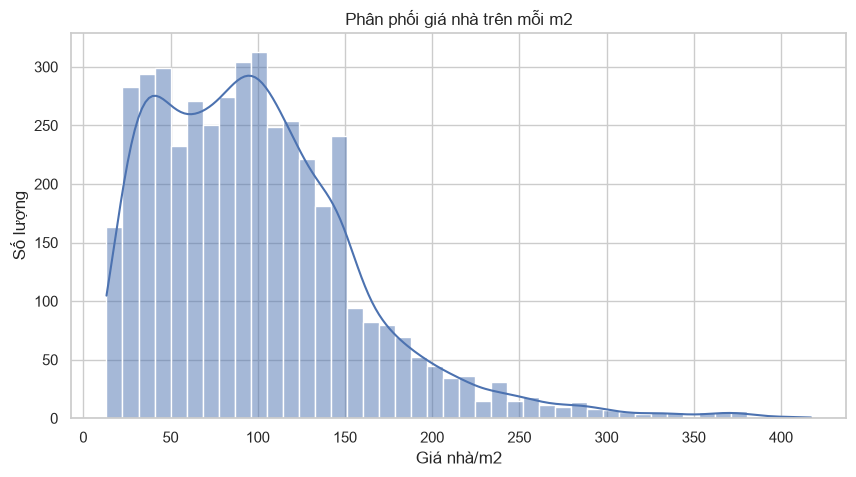

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Price_per_m2",
    kde=True
)

plt.title("Phân phối giá nhà trên mỗi m2")
plt.xlabel("Giá nhà/m2")
plt.ylabel("Số lượng")

plt.savefig(
    "../report/eda_phan_phoi_gia_nha_theo_m2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

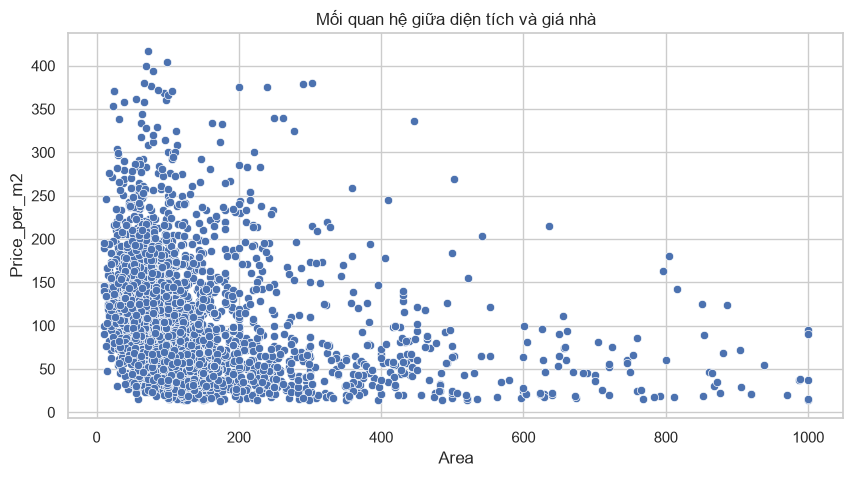

In [6]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Area",
    y="Price_per_m2"
)

plt.title("Mối quan hệ giữa diện tích và giá nhà")
plt.show()

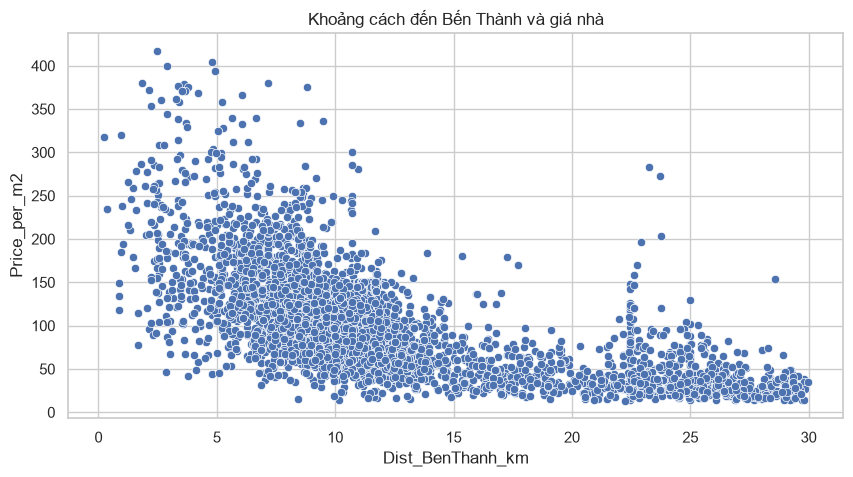

In [7]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Dist_BenThanh_km",
    y="Price_per_m2"
)

plt.title("Khoảng cách đến Bến Thành và giá nhà")
plt.show()

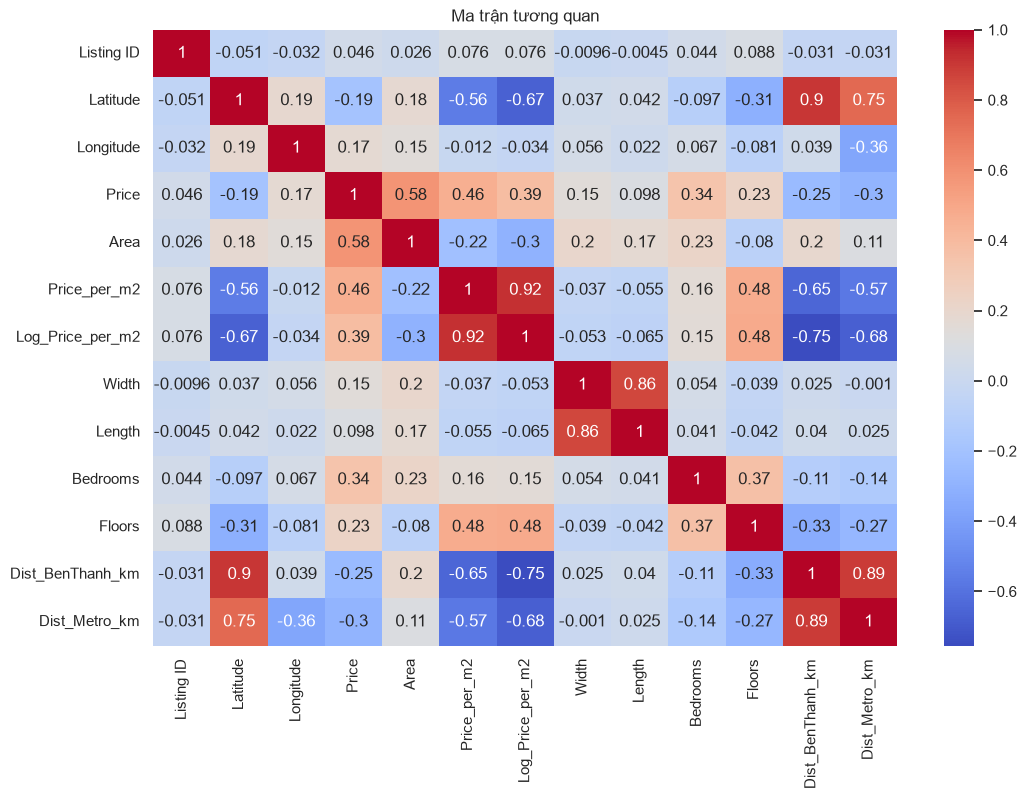

In [8]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Ma trận tương quan")
plt.show()

,count,mean,median,std
Position,,,,
Trong hẻm,1666,96.040145,94.206712,45.608853
Đường chính,1481,101.097124,92.181818,63.772835
Không rõ,1343,102.184536,88.362069,69.920603


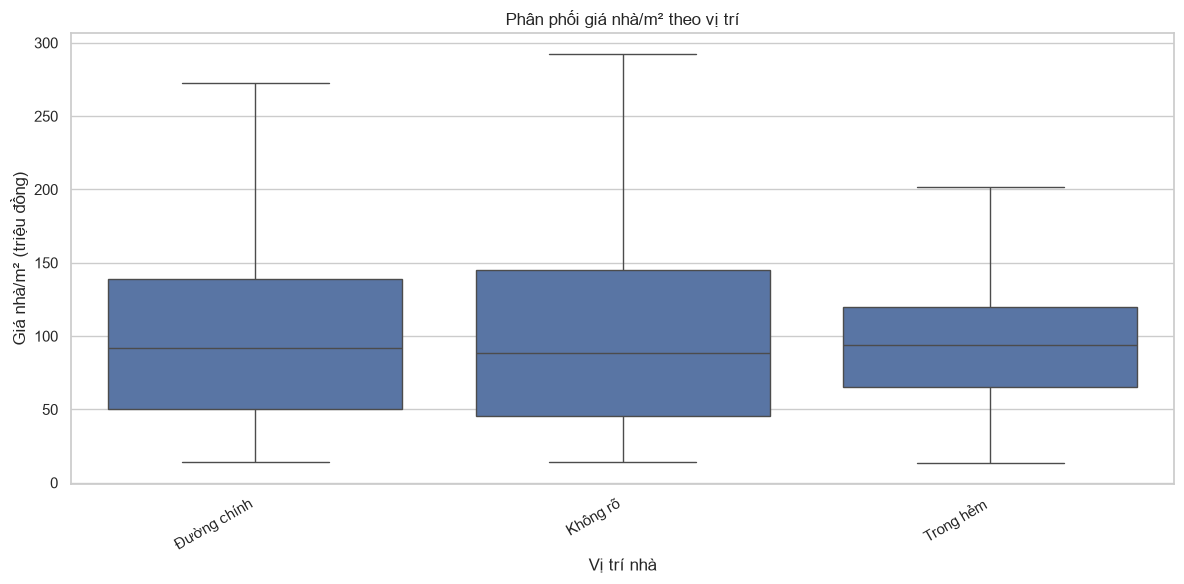

In [9]:
# kiểm tra dữ liệu vị trí
position_df = df.copy()

position_df["Position"] = (
    position_df["Position"]
    .fillna("Không rõ")
    .astype(str)
)

# chuyển giá/m2 sang kiểu số
position_df[GiaTheo_M2] = pd.to_numeric(
    position_df[GiaTheo_M2],
    errors="coerce"
)

position_df = position_df.dropna(
    subset=[GiaTheo_M2]
)

# thống kê giá theo vị trí
position_stats = position_df.groupby("Position")[GiaTheo_M2].agg(
    ["count", "mean", "median", "std"]
).sort_values("median", ascending=False)

display(position_stats)

position_stats.to_csv(
    "../report/eda_gia_theo_vi_tri.csv",
    encoding="utf-8-sig"
)

# vẽ biểu đồ
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=position_df,
    x="Position",
    y=GiaTheo_M2,
    showfliers=False
)

plt.title("Phân phối giá nhà/m² theo vị trí")
plt.xlabel("Vị trí nhà")
plt.ylabel("Giá nhà/m² (triệu đồng)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "../report/eda_gia_theo_vi_tri.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

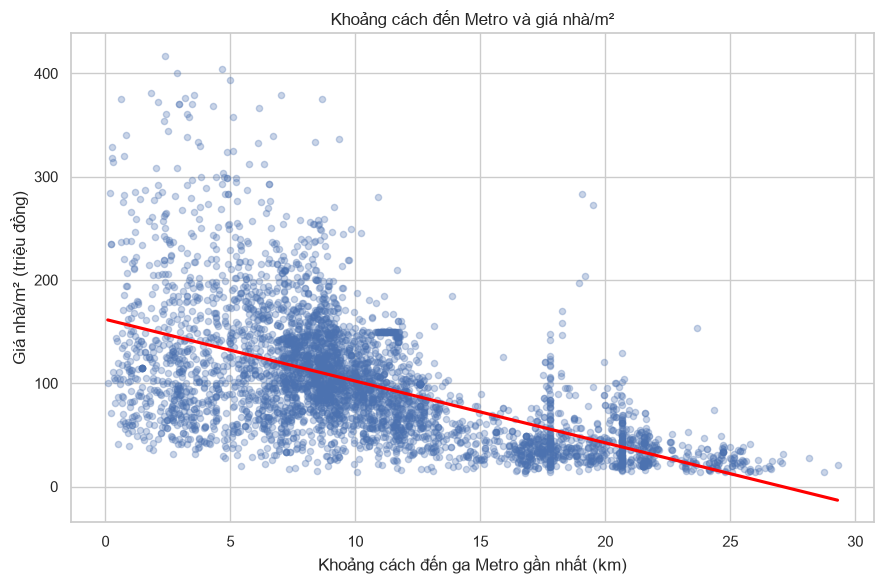

In [10]:
metro_df = df[
    ["Dist_Metro_km", GiaTheo_M2]
].copy()

metro_df["Dist_Metro_km"] = pd.to_numeric(
    metro_df["Dist_Metro_km"],
    errors="coerce"
)

metro_df[GiaTheo_M2] = pd.to_numeric(
    metro_df[GiaTheo_M2],
    errors="coerce"
)

metro_df = metro_df.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

plt.figure(figsize=(9, 6))

sns.regplot(
    data=metro_df,
    x="Dist_Metro_km",
    y=GiaTheo_M2,
    scatter_kws={"alpha": 0.3, "s": 20},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Khoảng cách đến Metro và giá nhà/m²")
plt.xlabel("Khoảng cách đến ga Metro gần nhất (km)")
plt.ylabel("Giá nhà/m² (triệu đồng)")

plt.tight_layout()

plt.savefig(
    "../report/eda_khoang_cach_metro_va_gia_nha.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

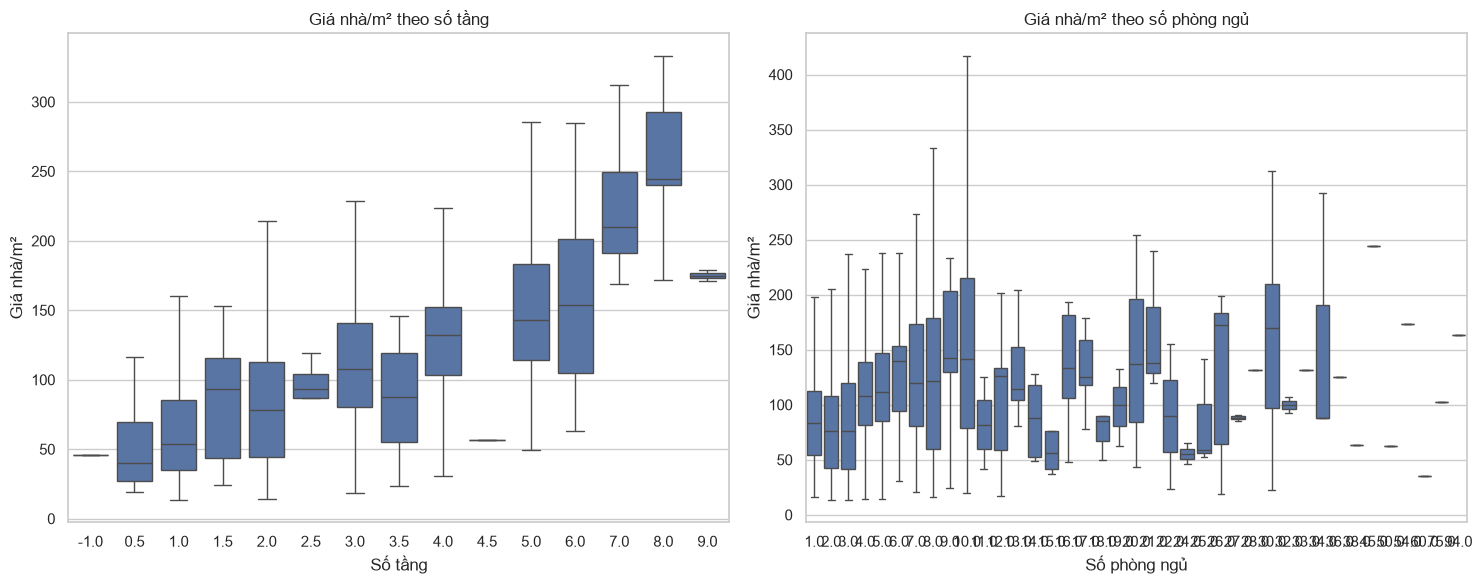

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# giá nhà theo số tầng
sns.boxplot(
    data=df,
    x="Floors",
    y=GiaTheo_M2,
    showfliers=False,
    ax=axes[0]
)

axes[0].set_title("Giá nhà/m² theo số tầng")
axes[0].set_xlabel("Số tầng")
axes[0].set_ylabel("Giá nhà/m²")

# giá nhà theo số phòng ngủ
sns.boxplot(
    data=df,
    x="Bedrooms",
    y=GiaTheo_M2,
    showfliers=False,
    ax=axes[1]
)

axes[1].set_title("Giá nhà/m² theo số phòng ngủ")
axes[1].set_xlabel("Số phòng ngủ")
axes[1].set_ylabel("Giá nhà/m²")

plt.tight_layout()

plt.savefig(
    "../report/eda_gia_theo_tang_va_theo_phong_ngu.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,MoiLienHe
Dist_BenThanh_km,-0.754977
Dist_Metro_km,-0.675443
Floors,0.482186
Area,-0.296378
Bedrooms,0.150610
Length,-0.065018
Width,-0.053047


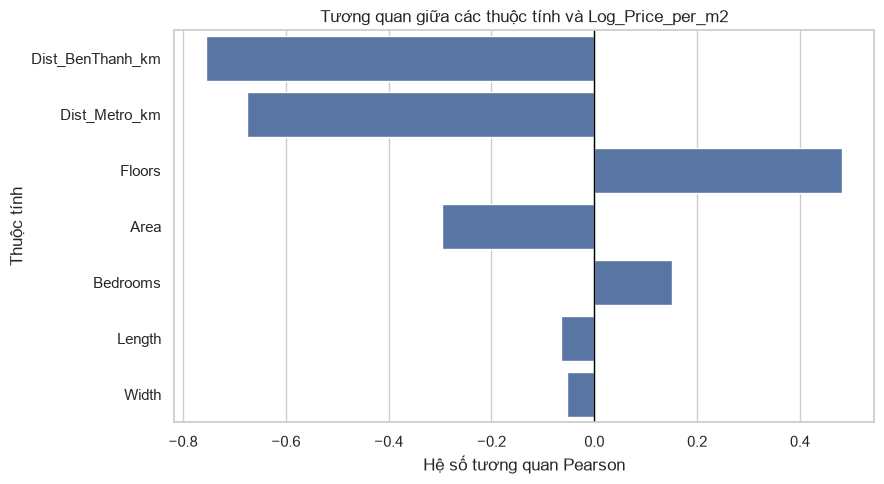

In [12]:
MoiLienHe_cols = [
    "Area",
    "Width",
    "Length",
    "Floors",
    "Bedrooms",
    "Dist_BenThanh_km",
    "Dist_Metro_km",
    MucTiec
]

# chỉ giữ các cột thực sự tồn tại
MoiLienHe_cols = [
    col for col in MoiLienHe_cols
    if col in df.columns
]

MoiLienHe_df = df[MoiLienHe_cols].copy()

MoiLienHe_df = MoiLienHe_df.apply(
    pd.to_numeric,
    errors="coerce"
)

MoiLienHe = MoiLienHe_df.corr()

# lấy tương quan với biến mục tiêu
MucTiec_corr = MoiLienHe[MucTiec].drop(MucTiec)

MucTiec_corr = MucTiec_corr.sort_values(
    key=abs,
    ascending=False
)

display(MucTiec_corr.to_frame("MoiLienHe"))

MucTiec_corr.to_csv(
    "../report/eda_tuong_quan_giua_thuoc_tinh.csv",
    encoding="utf-8-sig"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=MucTiec_corr.values,
    y=MucTiec_corr.index
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Tương quan giữa các thuộc tính và Log_Price_per_m2")
plt.xlabel("Hệ số tương quan Pearson")
plt.ylabel("Thuộc tính")

plt.tight_layout()

plt.savefig(
    "../report/eda_tuong_quan_giua_thuoc_tinh.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()